# Can a random forest predict the S&P 500’s next move?
Use information available at the end of a trading session to classify whether the **next trading session** closes higher. Compare a price-and-volume random forest, a rolling-feature random forest, and an always-up benchmark on the same dates.

Adapted from the [Dataquest project](https://www.dataquest.io/projects/portfolio-project-a-predict-the-stock-market-using-machine-learning/) and its solution notebook. The default uses [Dataquest’s historical CSV](https://github.com/dataquestio/project-walkthroughs/blob/master/sp_500/sp500.csv); set `USE_LIVE_YAHOO = True` to fetch a fresh history for a separate run. The probability cutoff of 0.60 follows the tutorial and is fixed before evaluation.

## 1. Load and clean daily prices

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.ticker import PercentFormatter
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, precision_score, recall_score

USE_LIVE_YAHOO = False
OHLCV = ["Close", "Volume", "Open", "High", "Low"]
DATA_URL = "https://raw.githubusercontent.com/dataquestio/project-walkthroughs/master/sp_500/sp500.csv"
cache = Path("dataquest_sp500.csv")

if USE_LIVE_YAHOO:
    import yfinance as yf
    raw = yf.Ticker("^GSPC").history(period="max", auto_adjust=False)
    raw.index = raw.index.tz_localize(None)
    # Skip the current New York calendar date, which may still be trading.
    today_ny = pd.Timestamp.now(tz="America/New_York").normalize().tz_localize(None)
    raw = raw.loc[raw.index < today_ny]
    source_name = "Yahoo Finance (^GSPC)"
else:
    raw = pd.read_csv(cache if cache.exists() else DATA_URL, index_col="Date", parse_dates=["Date"])
    source_name = "Dataquest historical snapshot"
    if not cache.exists():
        raw.to_csv(cache, index_label="Date")

prices = raw.loc[:, OHLCV].sort_index()
prices = prices.loc[~prices.index.duplicated(keep="last")]
prices = prices.apply(pd.to_numeric, errors="coerce")
if prices.empty or prices.isna().any().any():
    raise ValueError("Expected a nonempty daily OHLCV series with no missing values.")
prices = prices.loc["1990-01-01":].copy()
print(f"{source_name} | {len(prices):,} sessions | {prices.index.min():%Y-%m-%d} to {prices.index.max():%Y-%m-%d}")

Dataquest historical snapshot | 8,238 sessions | 1990-01-02 to 2022-09-12


## 2. Define the target and build features
`Target = 1` means the next trading session closes higher; a flat or lower close is `0`. Drop the latest row from evaluation because its next close is unknown. At close on day *t*, the outcome of day *t−1* is already known, so use `Target.shift(1)` before counting past up days.

In [2]:
data = prices.copy()
data["Tomorrow"] = data["Close"].shift(-1)
data["Target"] = (data["Tomorrow"] > data["Close"]).astype(int)
horizons = [2, 5, 60, 250, 1000]
rolling_features = []

for window in horizons:
    ratio = f"Close_Ratio_{window}"
    trend = f"Trend_{window}"
    data[ratio] = data["Close"] / data["Close"].rolling(window).mean()
    data[trend] = data["Target"].shift(1).rolling(window).sum()
    rolling_features.extend([ratio, trend])

labeled = data.dropna(subset=["Tomorrow"]).copy()
rolling_data = labeled.dropna(subset=rolling_features).copy()

## 3. Fit a baseline and backtest with an expanding training window
Start with a last-100-session baseline as in the tutorial. For the main comparison, the first evaluation date follows 2,500 feature-ready sessions. Refit each model every 250 trading sessions. The baseline can use its longer feature history, and both models predict the same evaluation dates. At each split we leave out the immediately preceding row because its label uses the first test day's close.

In [3]:
def baseline_model():
    return RandomForestClassifier(
        n_estimators=100, min_samples_split=100, random_state=1, n_jobs=2
    )

def rolling_model():
    return RandomForestClassifier(
        n_estimators=200, min_samples_split=50, random_state=1, n_jobs=2
    )

def fit_and_predict(train, test, features, model, threshold=None):
    model.fit(train[features], train["Target"])
    if threshold is None:
        return model.predict(test[features])
    probability_up = model.predict_proba(test[features])[:, 1]
    return (probability_up >= threshold).astype(int)

holdout = labeled.iloc[-100:]
holdout_pred = fit_and_predict(labeled.iloc[:-101], holdout, OHLCV, baseline_model())
print(f"Baseline precision on last 100 sessions: {precision_score(holdout['Target'], holdout_pred, zero_division=0):.1%}")

START, STEP, THRESHOLD = 2500, 250, 0.60
if len(rolling_data) <= START:
    raise ValueError("The dataset needs more than 2,500 feature-ready sessions.")
folds = []

for offset in range(START, len(rolling_data), STEP):
    test_fold = rolling_data.iloc[offset:offset + STEP]
    split = labeled.index.get_loc(test_fold.index[0])
    last_label_boundary = labeled.index[split - 1]
    baseline_train = labeled.loc[labeled.index < last_label_boundary]
    rolling_train = rolling_data.loc[rolling_data.index < last_label_boundary]
    folds.append(pd.DataFrame({
        "Actual": test_fold["Target"],
        "Always up": 1,
        "Baseline forest": fit_and_predict(baseline_train, test_fold, OHLCV, baseline_model()),
        "Rolling forest": fit_and_predict(
            rolling_train, test_fold, rolling_features, rolling_model(), THRESHOLD
        ),
    }))

predictions = pd.concat(folds)
print(f"Shared backtest: {len(predictions):,} sessions | {predictions.index.min():%Y-%m-%d} to {predictions.index.max():%Y-%m-%d}")

Baseline precision on last 100 sessions: 47.1%
Shared backtest: 4,737 sessions | 2003-11-14 to 2022-09-09


## 4. Compare precision, recall, and signal coverage
Precision answers “when the model predicts up, how often is it right?” Recall asks how many actual up days it identifies. Coverage is the share of sessions for which it predicts up. The 0.60 cutoff can trade away coverage and recall for higher precision.

In [4]:
models = ["Always up", "Baseline forest", "Rolling forest"]
actual = predictions["Actual"]
scores = pd.DataFrame({
    name: {
        "Up precision": precision_score(actual, predictions[name], zero_division=0),
        "Up recall": recall_score(actual, predictions[name], zero_division=0),
        "Accuracy": accuracy_score(actual, predictions[name]),
        "Up calls": int(predictions[name].sum()),
        "Up coverage": predictions[name].mean(),
    }
    for name in models
}).T

print(scores.to_string(formatters={
    "Up precision": "{:.1%}".format, "Up recall": "{:.1%}".format,
    "Accuracy": "{:.1%}".format, "Up coverage": "{:.1%}".format,
    "Up calls": "{:,.0f}".format,
}))

                Up precision Up recall Accuracy Up calls Up coverage
Always up              54.7%    100.0%    54.7%    4,737      100.0%
Baseline forest        54.7%     39.3%    49.0%    1,860       39.3%
Rolling forest         56.9%     17.3%    47.6%      786       16.6%


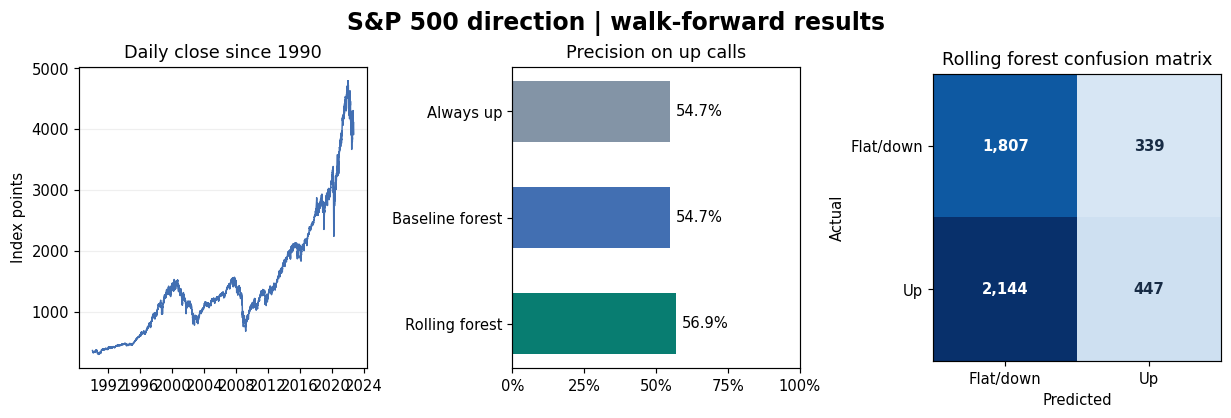

In [5]:
colors = ["#8394A6", "#426FB2", "#087D71"]
fig, axes = plt.subplots(1, 3, figsize=(11.5, 3.8), layout="constrained")
fig.suptitle("S&P 500 direction | walk-forward results", fontsize=16, fontweight="bold")

axes[0].plot(prices.index, prices["Close"], color=colors[1], linewidth=1)
axes[0].set(title="Daily close since 1990", ylabel="Index points")
axes[0].grid(axis="y", alpha=.2)

bars = axes[1].barh(models, scores["Up precision"], color=colors, height=.58)
axes[1].invert_yaxis()
axes[1].bar_label(bars, labels=[f"{v:.1%}" for v in scores["Up precision"]], padding=4)
axes[1].set(title="Precision on up calls", xlim=(0, 1))
axes[1].xaxis.set_major_formatter(PercentFormatter(1))
axes[1].set_xticks([0, .25, .5, .75, 1])

cm = confusion_matrix(actual, predictions["Rolling forest"], labels=[0, 1])
axes[2].imshow(cm, cmap="Blues", vmin=0)
for row in range(2):
    for col in range(2):
        count = cm[row, col]
        axes[2].text(col, row, f"{count:,}", ha="center", va="center",
                     color="white" if count > cm.max() / 2 else "#182C45", fontweight="bold")
axes[2].set(title="Rolling forest confusion matrix", xlabel="Predicted", ylabel="Actual",
            xticks=[0, 1], yticks=[0, 1],
            xticklabels=["Flat/down", "Up"], yticklabels=["Flat/down", "Up"])
plt.show()

## 5. Interpret the results
The always-up benchmark’s precision is the fraction of test days that actually close up. Compare model precision to that rate alongside recall and coverage. A model that makes few up calls may miss many up days, even when those calls are more precise.

The backtest measures classification performance on historical index data. It does not model position sizing, trading costs, or investment returns. An extension would tune the probability threshold on earlier dates, then evaluate it on a separate, later period.